# 2.0 - RFM Feature Engineering & K-Means Segmentation
**Week 2** | Features live in `src/features.py`, clustering in `src/modeling/segment.py`.

**Snapshot date:** all features use only orders **before** `config.SNAPSHOT_DATE`, so the same table can later be joined to a *future* churn label without leakage.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")
from src.modeling import segment as S
from sklearn.decomposition import PCA
tx = pd.read_csv(config.DATA_INTERIM / 'transactions_clean.csv', parse_dates=['order_date'])
customers = pd.read_csv(config.DATA_RAW / 'customers.csv', parse_dates=['signup_date'])
table = F.assemble_model_table(tx, customers, config.SNAPSHOT_DATE)
print(config.SNAPSHOT_DATE, table.shape); table[F.RFM_COLUMNS].describe().round(1)

2025-10-31 (4913, 20)


,recency_days,frequency,monetary
count,4913.0,4913.0,4913.0
mean,185.0,5.8,1619.3
std,184.5,6.7,2240.8
min,0.0,1.0,0.0
25%,28.0,1.0,237.4
50%,110.0,3.0,714.5
75%,319.0,8.0,2069.5
max,668.0,47.0,15788.8


## 1. RFM definition
* **Recency** - days since last order (lower = better)
* **Frequency** - number of distinct orders
* **Monetary** - net spend (returns excluded)

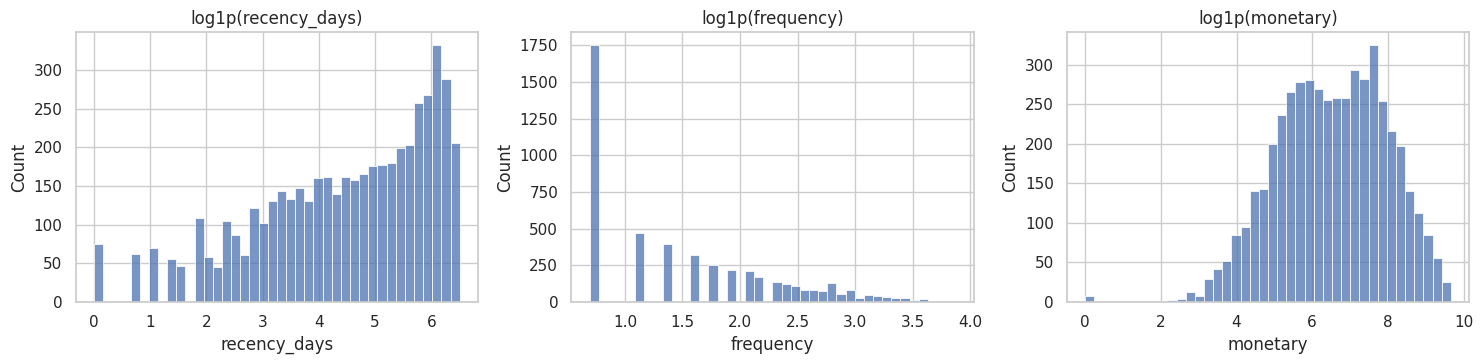

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, F.RFM_COLUMNS):
    sns.histplot(np.log1p(table[c]), bins=40, ax=a); a.set_title(f'log1p({c})')
plt.tight_layout(); save('05_rfm_distributions.png'); plt.show()

## 2. Choosing k - Elbow & Silhouette
Pipeline = `log1p -> StandardScaler -> KMeans`. We require **k >= 4** (project success metric: at least 4 distinct, actionable segments) and pick the k with the best silhouette in that range.

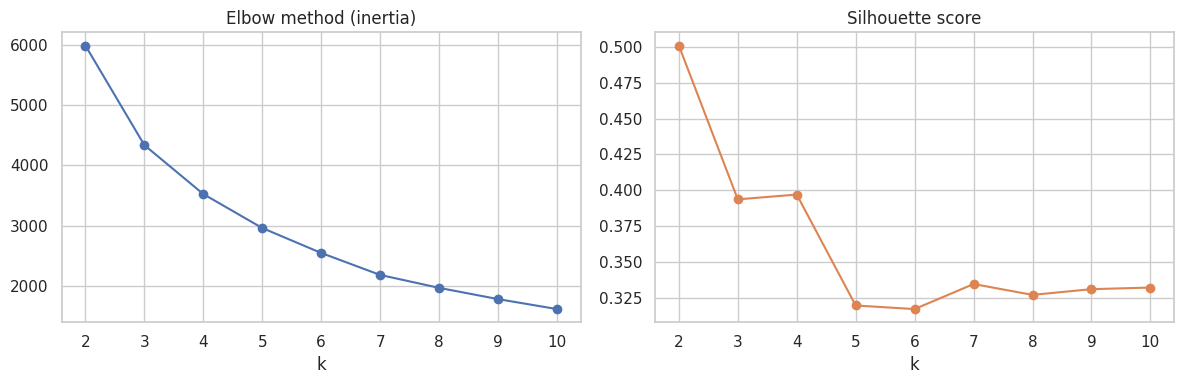

Chosen k = 4


,k,inertia,silhouette
0,2,5998.009,0.501
1,3,4339.270,0.394
2,4,3524.150,0.397
3,5,2958.347,0.319
4,6,2542.624,0.317
5,7,2176.821,0.334
6,8,1961.634,0.327
7,9,1774.073,0.331
8,10,1608.204,0.332


In [3]:
scores = S.evaluate_k(table)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(scores.k, scores.inertia, marker='o'); ax[0].set_title('Elbow method (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(scores.k, scores.silhouette, marker='o', color='C1'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.tight_layout(); save('06_elbow_silhouette.png'); plt.show()
best_k = int(scores[scores.k >= 4].sort_values('silhouette').iloc[-1].k)
print('Chosen k =', best_k); scores.round(3)

In [4]:
import joblib
seg_pipe = S.make_pipeline(best_k).fit(table[F.RFM_COLUMNS])
labels = seg_pipe.predict(table[F.RFM_COLUMNS])
names = S.name_clusters(table, labels)
table['segment'] = [names[c] for c in labels]
table.to_csv(config.DATA_PROCESSED / 'customer_segments.csv', index=False)
summary = S.segment_summary(table); summary.to_csv(config.DATA_PROCESSED / 'segment_summary.csv')
joblib.dump(seg_pipe, config.MODELS_DIR / 'kmeans_rfm_pipeline.joblib'); joblib.dump(names, config.MODELS_DIR / 'segment_names.joblib')
summary.drop(columns='recommended_action')

,customers,recency_median,frequency_median,monetary_median,revenue,pct_customers,pct_revenue
segment,,,,,,,
Champions,1051,16.0,14.0,4069.56,5138448.55,21.39,64.59
At Risk,1126,152.0,5.0,1255.18,1652141.77,22.92,20.77
Potential Loyalists,708,18.0,4.0,885.02,686672.29,14.41,8.63
Hibernating,2028,314.5,1.0,199.11,478403.23,41.28,6.01


## 3. Visualising the segments

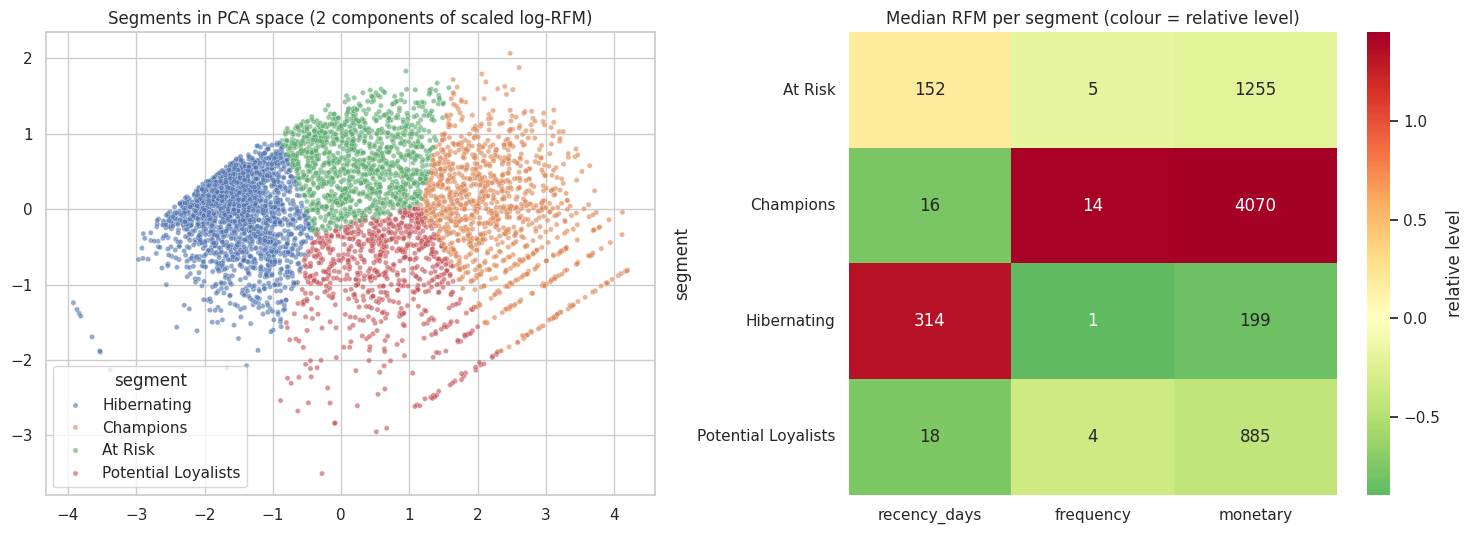

In [5]:
Z = seg_pipe[:-1].transform(table[F.RFM_COLUMNS])
xy = PCA(2, random_state=config.RANDOM_STATE).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(x=xy[:,0], y=xy[:,1], hue=table.segment, s=14, alpha=.6, ax=ax[0]); ax[0].set_title('Segments in PCA space (2 components of scaled log-RFM)')
prof = table.groupby('segment')[F.RFM_COLUMNS].median()
prof_z = (prof - prof.mean()) / prof.std()
sns.heatmap(prof_z, annot=prof.round(0), fmt='g', cmap='RdYlGn_r', center=0, ax=ax[1], cbar_kws={'label': 'relative level'}); ax[1].set_title('Median RFM per segment (colour = relative level)')
plt.tight_layout(); save('07_segments_pca_heatmap.png'); plt.show()

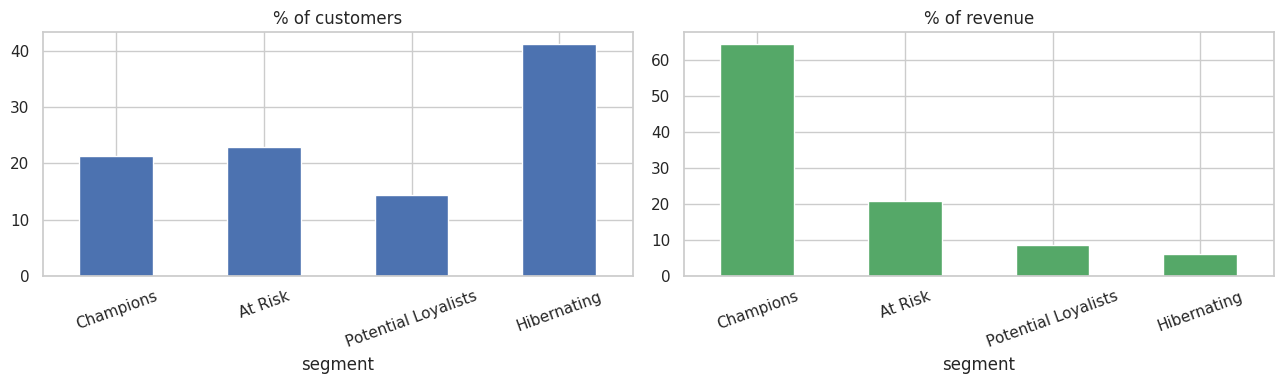

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
summary['pct_customers'].plot.bar(ax=ax[0], color='C0', title='% of customers'); summary['pct_revenue'].plot.bar(ax=ax[1], color='C2', title='% of revenue')
for a in ax: a.tick_params(axis='x', rotation=20)
plt.tight_layout(); save('08_segment_size_revenue.png'); plt.show()

## 4. Segment playbook (business recommendations)

In [7]:
for seg, row in summary.iterrows():
    print(f"{seg} ({row.pct_customers:.0f}% of customers, {row.pct_revenue:.0f}% of revenue)\n   -> {row.recommended_action}\n")

Champions (21% of customers, 65% of revenue)
   -> Reward and retain: VIP early access, loyalty tiers, referral incentives. Do NOT discount - they already buy at full price.

At Risk (23% of customers, 21% of revenue)
   -> Win back before they lapse: personalised 'we miss you' campaigns, targeted discounts, reminders based on their usual purchase gap.

Potential Loyalists (14% of customers, 9% of revenue)
   -> Build the habit: personalised second/third-purchase journeys, onboarding emails, time-limited reorder incentives.

Hibernating (41% of customers, 6% of revenue)
   -> Low-cost reactivation only: automated email/SMS flows, last-chance offers; suppress from paid-media spend if no response.



## Takeaways
* Segments are well separated and map directly to marketing actions.
* A small *Champions* group produces most revenue - protecting them is the top priority.
* *At Risk* customers (formerly strong, now recency-stale) are the best win-back target.

**Next:** predict who will churn (3.0).